How are ebooks rated differently than physical books?

- is_ebook
- average_rating

In [69]:
import pandas as pd

books = pd.read_csv("../data/processed/sampled_books.csv")

# remove all other columns except for is_ebook, average_rating
books = books[['is_ebook', 'average_rating']]

before = books.shape

# convert to numeric and boolean respectively 
books["average_rating"] = pd.to_numeric(books["average_rating"], errors="coerce")

# remove books outside of ratings range
books = books[books["average_rating"].between(1.0, 5.0)]

# shape after removing invalid data
after = books.shape

print(f'Removed {before[0] - after[0]} rows of invalid data. Shape is now {after}')


Removed 356 rows of invalid data. Shape is now (117677, 2)


In [70]:
ebooks = books[books["is_ebook"]==True]
not_ebooks = books[books["is_ebook"]==False]

print("DESCRIPTIVE STATISTICS")

print("ebook = True", "len =", len(ebooks)) 
print(f'\tMean = {ebooks["average_rating"].mean()}')
print(f'\tSTD = {ebooks["average_rating"].std()}')
print(f'\tMedian = {ebooks["average_rating"].median()}')

print("ebook = False", "len =", len(not_ebooks))
print(f'\tMean = {not_ebooks["average_rating"].mean()}')
print(f'\tSTD = {not_ebooks["average_rating"].std()}')
print(f'\tMedian = {not_ebooks["average_rating"].median()}')


DESCRIPTIVE STATISTICS
ebook = True len = 33865
	Mean = 3.9319462571976964
	STD = 0.5183480816064225
	Median = 3.97
ebook = False len = 83812
	Mean = 3.856198396411015
	STD = 0.4907569073297929
	Median = 3.9


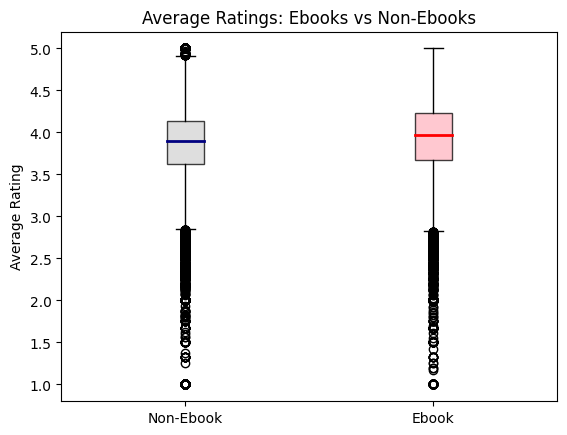

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

bp = plt.boxplot(
    [not_ebooks["average_rating"], ebooks["average_rating"]],
    labels=["Non-Ebook", "Ebook"],
    patch_artist=True
)
bp["boxes"][0].set(facecolor="lightgray", alpha=0.75)
bp["boxes"][1].set(facecolor="lightpink", alpha=0.75)

bp["medians"][0].set(color="navy", linewidth=2)
bp["medians"][1].set(color="red", linewidth=2)

plt.ylabel("Average Rating")
plt.title("Average Ratings: Ebooks vs Non-Ebooks")
plt.show()


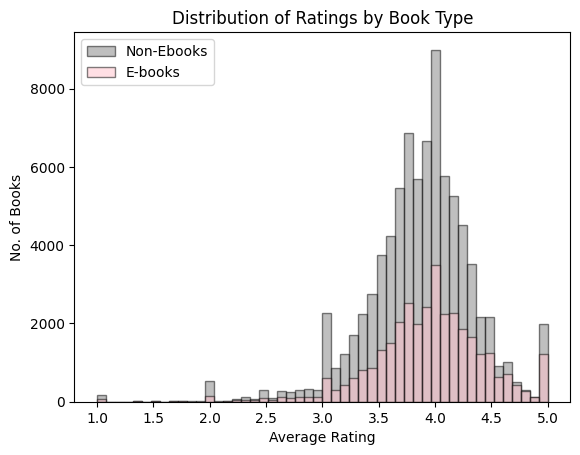

In [72]:
plt.hist(not_ebooks["average_rating"], bins=50, label="Non-Ebooks", color="gray", edgecolor="black", alpha=0.5)
plt.hist(ebooks["average_rating"], bins=50, label="E-books", color="pink", edgecolor="black", alpha=0.5)
plt.title('Distribution of Ratings by Book Type')
plt.ylabel('No. of Books')
plt.xlabel('Average Rating')
plt.legend()
plt.show()


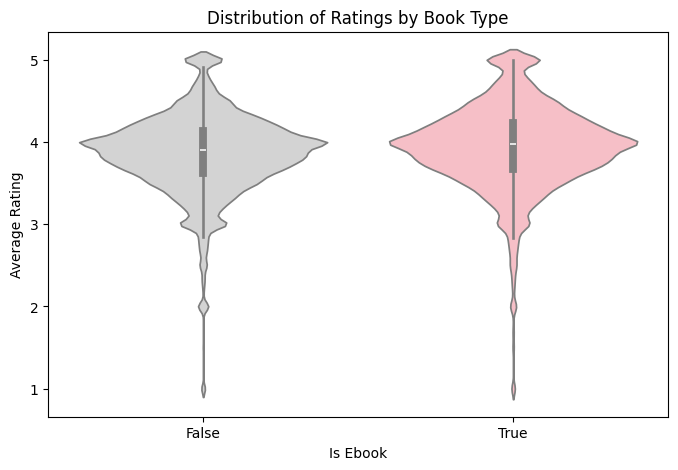

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.violinplot(
    data=books,
    x="is_ebook",
    y="average_rating",
    palette={
        "False": "lightgray",
        "True": "lightpink"
    }
)

plt.xlabel("Is Ebook")
plt.ylabel("Average Rating")
plt.title("Distribution of Ratings by Book Type")

plt.show()
